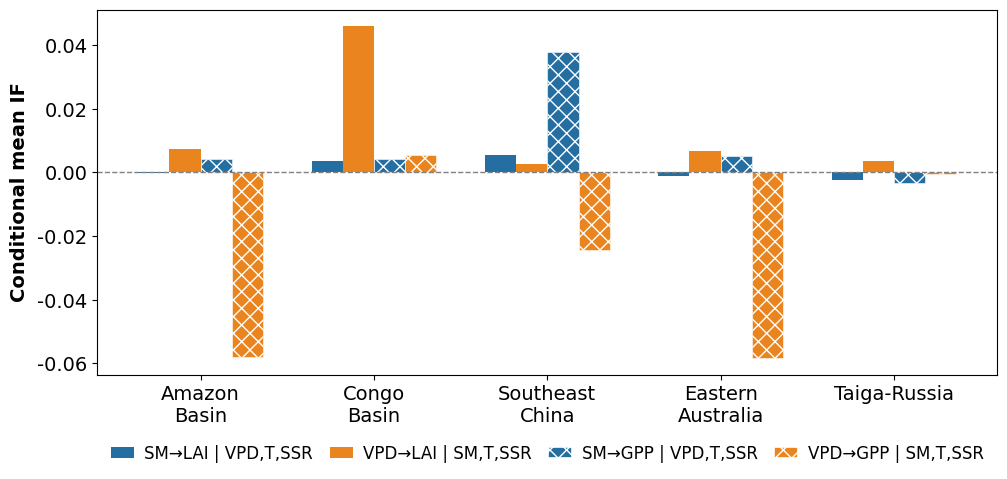

[Saved] E:\CAZ-Again\Figure3\IF_mean_DroughtOnly__Grouped_5regions_x4couplings_CrispHatchLegend.png
Done: Legend visibility fix completed successfully.


In [3]:
#3a

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path
import scipy.io as sio
import re

# --------------------------- Config ---------------------------
BASE = Path(r"E:/CAZ-Again")
mat_path = BASE / "Fareeha_data_SM_VPD_1981_2018.mat"
if_path  = BASE / "IF_Couplings.xlsx"

FIG_DIR = BASE / "Figure3"
FIG_DIR.mkdir(exist_ok=True, parents=True)
SAVE_DPI = 400

# Thin canvas to match your style
FIGSIZE_DROUGHT_SINGLE = (10, 5)
GROUP_WIDTH = 0.72   # grouped width per region (0..1)

# ---- Typography ----
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titleweight": "normal",
    "axes.labelweight": "normal",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "figure.facecolor": "white",
    "savefig.facecolor": "white",

    # Increased sizes
    "font.size": 16,        # Base size
    "axes.titlesize": 16,   # Axis titles
    "axes.labelsize": 14,   # x/y labels
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
})

def _safe_name(name: str) -> str:
    return re.sub(r'[^A-Za-z0-9._-]+', '_', name)[:150]

# --------------------------- Labels & palettes ---------------------------
REGIONS = ["Amazon","Congo","China","QL","Taiga"]
REGION_PRETTY = {
    "Amazon": "Amazon Basin",
    "Congo": "Congo Basin",
    "China": "Southeast China",
    "QL": "Eastern Australia",
    "Taiga": "Russia's Taiga"
}
REGION_TICKLABELS_MAP = {
    "Amazon Basin": "Amazon\nBasin",
    "Congo Basin": "Congo\nBasin",
    "Southeast China": "Southeast\nChina",
    "Eastern Australia": "Eastern\nAustralia",
    "Russia's Taiga": "Taiga-Russia",
}

# Couplings (order is bar order within each region)
COUPLINGS = [
    ("LAI", "SM→LAI | VPD,T,SSR", "SM-LAI|VPD,T,SSR"),
    ("LAI", "VPD→LAI | SM,T,SSR", "VPD-LAI|SM,T,SSR"),
    ("GPP", "SM→GPP | VPD,T,SSR", "SM-GPP|VPD,T,SSR"),
    ("GPP", "VPD→GPP | SM,T,SSR", "VPD-GPP|SM,T,SSR"),
]

COUPLING_SHORT = {
    "SM→LAI | VPD,T,SSR": "SM→LAI | VPD,T,SSR",
    "VPD→LAI | SM,T,SSR": "VPD→LAI | SM,T,SSR",
    "SM→GPP | VPD,T,SSR": "SM→GPP | VPD,T,SSR",
    "VPD→GPP | SM,T,SSR": "VPD→GPP | SM,T,SSR",
}

# ---- Colors and Styles Configuration ----
SM_HEX  = "#256EA2"
VPD_HEX = "#ea841e"

# Unified opacity across both pairs to remove the distracting light/dark colors
ALPHA_SM_LAI   = 1.00
ALPHA_SM_GPP   = 1.00  
ALPHA_VPD_LAI  = 1.00
ALPHA_VPD_GPP  = 1.00  

WHITE_HATCH_HEX = "#ffffff"

COUPLING_STYLE = {
    "SM→LAI | VPD,T,SSR": {"color": SM_HEX,  "alpha": ALPHA_SM_LAI,  "hatch": "",   "hatch_color": "none"},
    "SM→GPP | VPD,T,SSR": {"color": SM_HEX,  "alpha": ALPHA_SM_GPP,  "hatch": "xx", "hatch_color": WHITE_HATCH_HEX},  
    "VPD→LAI | SM,T,SSR": {"color": VPD_HEX, "alpha": ALPHA_VPD_LAI, "hatch": "",   "hatch_color": "none"},
    "VPD→GPP | SM,T,SSR": {"color": VPD_HEX, "alpha": ALPHA_VPD_GPP, "hatch": "xx", "hatch_color": WHITE_HATCH_HEX} 
}

DROUGHT_NAME = "Drought–Demand"

# --------------------------- Load drivers & IF ---------------------------
mat = sio.loadmat(str(mat_path), squeeze_me=True)

def get_series(prefix, region_key):
    keys = {k.lower(): k for k in mat.keys()}
    want = f"{prefix}_{region_key}".lower()
    if want in keys:
        arr = np.ravel(np.array(mat[keys[want]], dtype=float))
        idx = pd.period_range("1982-01","2018-12",freq="M").to_timestamp()
        n = min(len(arr), len(idx))
        return pd.Series(arr[:n], index=idx[:n], name=prefix)
    return None

drivers = {}
for reg in REGIONS:
    sm = get_series("SM", reg); vpd = get_series("VPD", reg)
    if sm is not None and vpd is not None:
        drivers[reg] = {"SM": sm.astype(float), "VPD": vpd.astype(float)}

LAI_df = pd.read_excel(if_path, sheet_name="SM'VPD-LAI", header=[0,1])
GPP_df = pd.read_excel(if_path, sheet_name="SM'VPD-GPP", header=[0,1])

def _parse_time(col0):
    t = pd.to_datetime(col0, errors="coerce")
    if t.isna().all():
        t = pd.to_datetime(col0, unit="D", origin="1899-12-30", errors="coerce")
    return t.dt.to_period("M").dt.to_timestamp()

LAI_df = LAI_df.set_index(_parse_time(LAI_df.iloc[:,0])).iloc[:,1:]
GPP_df = GPP_df.set_index(_parse_time(GPP_df.iloc[:,0])).iloc[:,1:]

NAME_MAP = {"AMAZON":"Amazon","CONGO":"Congo","CHINA":"China",
            "AUSTRALIA":"QL","WET TROPICS - AUSTRALIA":"QL",
            "RUSSIA":"Taiga","RUSSIA'S TAIGA":"Taiga","TAIGA":"Taiga"}

def pick_if_series(df, canon_region, pattern):
    for (reg_lbl, key) in df.columns:
        if NAME_MAP.get(reg_lbl, reg_lbl.title()) == canon_region and key == pattern:
            s = df[(reg_lbl, key)].astype(float).copy()
            s.index = s.index.to_period("M").to_timestamp()
            return s.groupby(s.index).mean().rename("IF")
    return None

def classify_regimes(sm, vpd):
    df = pd.concat([sm.rename("SM"), vpd.rename("VPD")], axis=1).dropna()
    qsm1,qsm2 = df.SM.quantile([1/3,2/3]); qv1,qv2 = df.VPD.quantile([1/3,2/3])
    reg = pd.Series("Other", index=df.index, dtype=object)
    reg[(df.SM<=qsm1) & (df.VPD>=qv2)] = "Drought–Demand"
    reg[(df.SM>=qsm2) & (df.VPD<=qv1)] = "Wet–Relief"
    reg[(df.SM<=qsm1) & (df.VPD<=qv1)] = "Mixed-Low"
    reg[(df.SM>=qsm2) & (df.VPD>=qv2)] = "Mixed-High"
    return df.index, reg

# --------------------------- Build drought-only matrix ---------------------------
summary_rows = []
for reg in REGIONS:
    if reg not in drivers:
        continue
    sm = drivers[reg]["SM"]; vpd = drivers[reg]["VPD"]
    _, regimes = classify_regimes(sm, vpd)

    for target, pretty, key in COUPLINGS:
        dfIF = LAI_df if target=="LAI" else GPP_df
        s_if = pick_if_series(dfIF, reg, key.replace("→","-").replace(" | ", "|"))
        if s_if is None:
            continue
        s_if = s_if.reindex(sm.index)
        dfj = pd.concat([s_if.rename("IF"), regimes.rename("Regime")], axis=1).dropna()
        if dfj.empty:
            continue
        means = dfj.groupby("Regime")["IF"].mean()
        if DROUGHT_NAME in means.index:
            summary_rows.append({
                "Region": REGION_PRETTY[reg],
                "Coupling": pretty,
                "MeanIF": float(means.loc[DROUGHT_NAME]),
            })

summary = pd.DataFrame(summary_rows)

def drought_matrix(summary_df, region_order, couplings):
    M = np.zeros((len(region_order), len(couplings)))
    for i, rpretty in enumerate(region_order):
        for j, (_, pretty, _) in enumerate(couplings):
            v = summary_df.loc[
                (summary_df["Region"]==rpretty) &
                (summary_df["Coupling"]==pretty),
                "MeanIF"
            ]
            M[i, j] = float(v.values[0]) if not v.empty else 0.0
    return M

# --------------------------- Plot ---------------------------
def plot_drought_grouped_single(summary_df, couplings, region_order, save_dir=FIG_DIR, show_picture=True):
    M = drought_matrix(summary_df, region_order, couplings)

    n_regions, n_couplings = M.shape
    x = np.arange(n_regions)
    bar_w = GROUP_WIDTH / n_couplings
    offsets = (np.arange(n_couplings) - (n_couplings-1)/2) * bar_w

    region_ticklabels = [REGION_TICKLABELS_MAP[r] for r in region_order]
    fig, ax = plt.subplots(figsize=FIGSIZE_DROUGHT_SINGLE)

    # --- y-axis: bold heading ---
    ax.set_ylabel("Conditional mean IF", labelpad=6, fontweight="bold")

    # Plot bars per coupling
    handles, labels = [], []
    for j, (_, pretty, _) in enumerate(couplings):
        yvals = M[:, j]
        style = COUPLING_STYLE[pretty]
        
        # Change the hatch color dynamically using rcParams context
        with plt.rc_context({'hatch.color': style['hatch_color']}):
            bars = ax.bar(x + offsets[j], yvals, bar_w,
                          label=COUPLING_SHORT[pretty],
                          color=style["color"], edgecolor=style['hatch_color'] if style['hatch'] else 'none', 
                          linewidth=0.4 if style['hatch'] else 0, 
                          alpha=style["alpha"], hatch=style["hatch"])

        # ADJUSTMENT: Raised legend patch linewidth to 1.2 so white crosses stand out bold and clear
        handles.append(Rectangle((0,0), 1, 1, facecolor=style["color"], 
                                 alpha=style["alpha"], hatch=style["hatch"], 
                                 edgecolor=style['hatch_color'] if style['hatch'] else 'none',
                                 linewidth=1.2 if style['hatch'] else 0))
        labels.append(COUPLING_SHORT[pretty])

    # Axes styling
    ax.axhline(0, color="0.5", linewidth=1, linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels(region_ticklabels, color="black")
    for side in ["top","right","left","bottom"]:
        ax.spines[side].set_color("black")
    ax.tick_params(axis="both", colors="black")
    plt.setp(ax.get_yticklabels(), fontweight="normal")

    # Anchored axis legend centered perfectly below the visual plot area
    ax.legend(handles, labels, ncol=len(couplings), frameon=False,
              loc="upper center", bbox_to_anchor=(0.5, -0.15),
              handlelength=1.4, handletextpad=0.6, columnspacing=1.0,
              labelcolor="black")

    plt.subplots_adjust(bottom=0.22, top=0.95, left=0.08, right=0.98, wspace=0.15)

    fname = save_dir / "IF_mean_DroughtOnly__Grouped_5regions_x4couplings_CrispHatchLegend.png"
    fig.savefig(fname, dpi=SAVE_DPI, bbox_inches="tight")
    if show_picture:
        plt.show()
    plt.close(fig)
    print(f"[Saved] {fname}")

# --------------------------- Run ---------------------------
region_order = [
    "Amazon Basin", "Congo Basin", "Southeast China",
    "Eastern Australia", "Russia's Taiga"
]
plot_drought_grouped_single(summary, COUPLINGS, region_order, show_picture=True)

print("Done: Legend visibility fix completed successfully.")

[Saved full Figure B successfully] E:\CAZ-Again\Figure3\EventAligned_Composites_AllRegions_FigureB.png


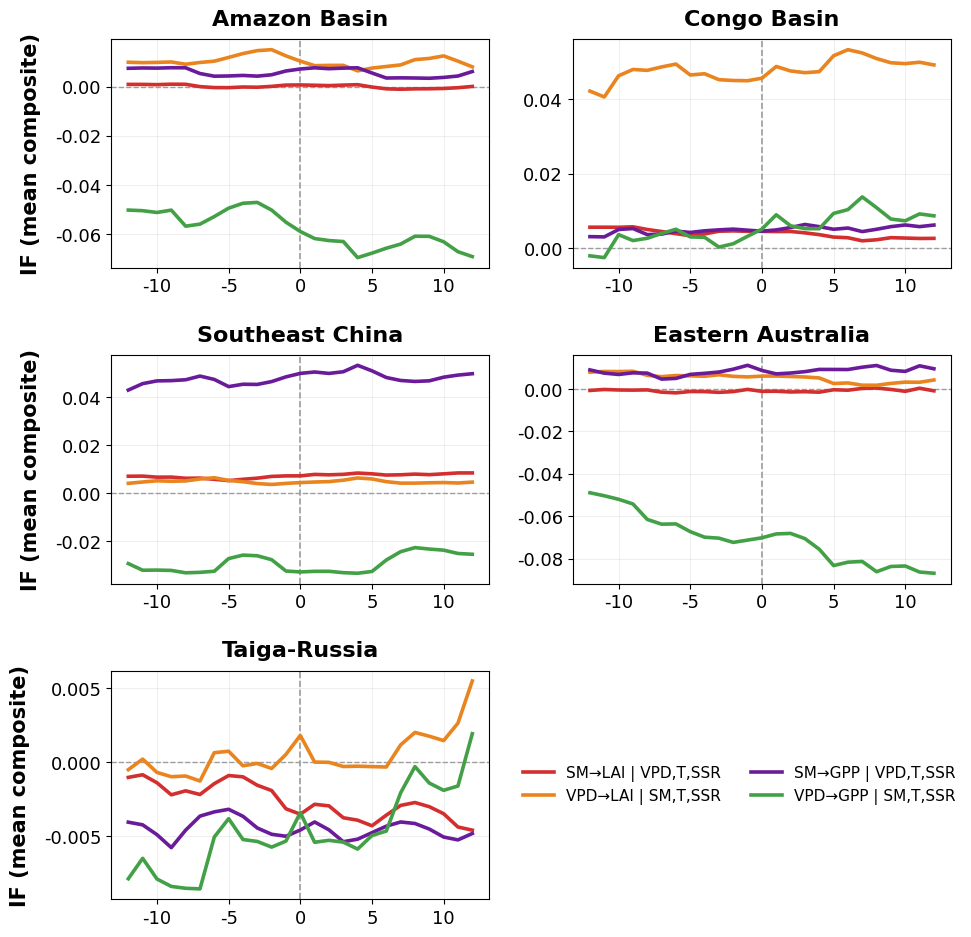

In [5]:
#3b
# --------------------------- Event-Aligned Composites ---------------------------

import matplotlib as mpl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path
import scipy.io as sio
import re

# ---- Typography ----
mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 13,                # Base structural font size
    "axes.titlesize": 16,           # Box titles increased for clear visibility
    "axes.titleweight": "bold",
    "axes.labelsize": 15,           # Y-axis label headings increased for clear visibility
    "axes.labelweight": "bold",     # Bold x/y labels
    "xtick.labelsize": 13,          # Tick numbers increased slightly
    "ytick.labelsize": 13,          # Tick numbers increased slightly
    "legend.fontsize": 11,          
    "mathtext.default": "regular",  
    "axes.unicode_minus": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,

    # Force black text everywhere
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.edgecolor": "black",

    # Draw grid/ticks/zero-lines below plot artists
    "axes.axisbelow": True,
})

# Optional widths for spines/ticks/grid
SPINE_W = 0.8
TICK_W  = 0.8
GRID_W  = 0.6
mpl.rcParams.update({
    "axes.linewidth": SPINE_W,
    "grid.linewidth": GRID_W,
    "xtick.major.width": TICK_W,
    "ytick.major.width": TICK_W,
})

# Line widths
LINE_W        = 2.6   
ZERO_VLINE_W  = 1.2   
ZERO_HLINE_W  = 1.0   

# ================================ Imports =====================================
# ---------------- Paths ----------------
BASE = Path("E:/CAZ-Again")
mat_path = BASE / "Fareeha_data_SM_VPD_1981_2018.mat"
if_path  = BASE / "IF_Couplings.xlsx"

# Output folder + image quality
FIG_DIR = BASE / "Figure3"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SAVE_DPI   = 400

# Equal padding controls
BOX_EXPAND = 1.06
PAD_INCHES = 0.06

def _safe(name: str) -> str:
    return re.sub(r'[^A-Za-z0-9._-]+', '_', name).strip('_')

# ---------------- Regions & naming ----------------
regions = ["Amazon Basin","Congo Basin","Southeast China","Eastern Australia","Taiga-Russia"]
REG_MAP_IN = {
    "Amazon Basin": "Amazon",
    "Congo Basin": "Congo",
    "Southeast China": "China",
    "Eastern Australia": "QL",
    "Taiga-Russia": "Taiga",
}
NAME_MAP_XLS = {
    "AMAZON": "Amazon",
    "CONGO": "Congo",
    "CHINA": "China",
    "AUSTRALIA": "QL",
    "WET TROPICS - AUSTRALIA": "QL",
    "RUSSIA": "Taiga",
    "RUSSIA'S TAIGA": "Taiga",
    "TAIGA": "Taiga",
}

# ---------------- Load drivers (SM, VPD) ----------------
mat = sio.loadmat(str(mat_path), squeeze_me=True)

def get_series(prefix, region_key):
    keys = {k.lower(): k for k in mat.keys()}
    want = f"{prefix}_{region_key}".lower()
    if want in keys:
        arr = np.ravel(np.array(mat[keys[want]], dtype=float))
        idx = pd.period_range("1982-01","2018-12",freq="M").to_timestamp()
        n = min(len(arr), len(idx))
        return pd.Series(arr[:n], index=idx[:n], name=prefix)
    return None

drivers = {}
for r in regions:
    rk = REG_MAP_IN[r]
    sm = get_series("SM", rk); vpd = get_series("VPD", rk)
    if sm is not None and vpd is not None:
        drivers[r] = {"SM": sm.astype(float), "VPD": vpd.astype(float)}

# ---------------- Build regimes via terciles ----------------
def classify_regimes(sm, vpd):
    df = pd.concat([sm.rename("SM"), vpd.rename("VPD")], axis=1).dropna()
    qsm1,qsm2 = df.SM.quantile([1/3,2/3]); qv1,qv2 = df.VPD.quantile([1/3,2/3])
    lab = pd.Series("Other", index=df.index, dtype=object)
    lab[(df.SM<=qsm1) & (df.VPD>=qv2)] = "Drought Regime"
    lab[(df.SM>=qsm2) & (df.VPD<=qv1)] = "Wet–Relief"
    lab[(df.SM<=qsm1) & (df.VPD<=qv1)] = "Mixed-Low"
    lab[(df.SM>=qsm2) & (df.VPD>=qv2)] = "Mixed-High"
    return lab.reindex(sm.index).fillna("Other")

regime_ts_reg = {}
for r in regions:
    if r in drivers:
        sm = drivers[r]["SM"]; vpd = drivers[r]["VPD"]
        regime_ts_reg[r] = classify_regimes(sm, vpd)

# ---------------- Load IF workbook ----------------
LAI = pd.read_excel(if_path, sheet_name="SM'VPD-LAI", header=[0,1])
GPP = pd.read_excel(if_path, sheet_name="SM'VPD-GPP", header=[0,1])

def fix_time(df):
    t = pd.to_datetime(df.iloc[:,0], errors="coerce")
    if t.isna().all():
        t = pd.to_datetime(df.iloc[:,0], unit="D", origin="1899-12-30", errors="coerce")
    t = t.dt.to_period("M").dt.to_timestamp()
    return df.set_index(t).iloc[:,1:]

LAI = fix_time(LAI); GPP = fix_time(GPP)

def pick_if(df, canon_region, key):
    for (lbl, k) in df.columns:
        if NAME_MAP_XLS.get(lbl, lbl.title()) == canon_region and k == key:
            s = df[(lbl, k)].astype(float).copy()
            s.index = s.index.to_period("M").to_timestamp()
            return s.groupby(s.index).mean()
    return None

# ---------------- Build IFs dict per region ----------------
IFs = {}
for r in regions:
    if r not in drivers: continue
    IFs[r] = {}
    s1 = pick_if(LAI, REG_MAP_IN[r], "SM-LAI|VPD,T,SSR")
    s2 = pick_if(LAI, REG_MAP_IN[r], "VPD-LAI|SM,T,SSR")
    s3 = pick_if(GPP, REG_MAP_IN[r], "SM-GPP|VPD,T,SSR")
    s4 = pick_if(GPP, REG_MAP_IN[r], "VPD-GPP|SM,T,SSR")
    
    idx = drivers[r]["SM"].index
    if s1 is not None: IFs[r]["SM→LAI | VPD,T,SSR"] = s1.reindex(idx)
    if s2 is not None: IFs[r]["VPD→LAI | SM,T,SSR"] = s2.reindex(idx)
    if s3 is not None: IFs[r]["SM→GPP | VPD,T,SSR"] = s3.reindex(idx)
    if s4 is not None: IFs[r]["VPD→GPP | SM,T,SSR"] = s4.reindex(idx)

# ---------------- Composite helpers ----------------
WINDOW = 12
PERSIST = 2

def find_entries(regime_series, target="Drought Regime", persist=PERSIST):
    r = regime_series.astype(str).values
    entries = []
    for i in range(1, len(r)):
        if r[i] == target and r[i-1] != target:
            tail = r[i:i+persist]
            if len(tail) == persist and np.all(tail == target):
                entries.append(i)
    return np.array(entries, dtype=int)

def composite_mean(if_series, entries, window=WINDOW):
    x = []
    for ix in entries:
        lo, hi = ix - window, ix + window
        if lo >= 0 and hi < len(if_series):
            seg = if_series.iloc[lo:hi+1].astype(float).values
            if np.isfinite(seg).all():
                x.append(seg)
    if len(x) == 0:
        return None
    X = np.vstack(x)
    return X.mean(axis=0)

XLABEL_TEXT = "Months from entry into Dry-hot Regime (0 = onset)"
YLABEL_TEXT = "IF (mean composite)"

def plot_region(ax, region_name, regime_series, IFs_dict, labels_dict, colors_dict):
    ax.set_axisbelow(True)
    ax.axvline(0, ls="--", lw=ZERO_VLINE_W, color="0.6", zorder=0)
    ax.axhline(0, ls="--",  lw=ZERO_HLINE_W, color="0.6", zorder=0)

    entries = find_entries(regime_series, "Drought Regime", PERSIST)
    t = np.arange(-WINDOW, WINDOW+1)
    for key in ["SM→LAI | VPD,T,SSR", "VPD→LAI | SM,T,SSR",
                "SM→GPP | VPD,T,SSR", "VPD→GPP | SM,T,SSR"]:
        s = IFs_dict.get(key, None)
        if s is None:
            continue
        m = composite_mean(s, entries, WINDOW)
        if m is not None:
            ax.plot(t, m, linewidth=LINE_W, label=labels_dict[key], color=colors_dict[key], zorder=3)

    ax.set_xticks([-10, -5, 0, 5, 10])
    ax.grid(True, which="both", axis="both", alpha=0.25, zorder=0)
    ax.set_title(region_name, pad=10)

# Colors restored restrictively
cmap = {
    "SM→LAI | VPD,T,SSR": "#D32F2F",  
    "VPD→LAI | SM,T,SSR": "#ea841e",  
    "SM→GPP | VPD,T,SSR": "#6A1B9A",  
    "VPD→GPP | SM,T,SSR": "#43A047",  
}
order = ["SM→LAI | VPD,T,SSR", "VPD→LAI | SM,T,SSR",
         "SM→GPP | VPD,T,SSR", "VPD→GPP | SM,T,SSR"]

# ---------------- Plot: 3x2 grid ----------------
FIGSIZE = (10, 10)
fig, axes = plt.subplots(3, 2, figsize=FIGSIZE)
axes_flat = axes.ravel()

# Plot first five panels
for i, reg in enumerate(regions):
    plot_region(axes_flat[i], reg, regime_ts_reg[reg], IFs[reg], {k:k for k in cmap}, cmap)

# Panel 6 for your two-row layout legend
legend_ax = axes_flat[-1]
legend_ax.axis("off")
handles = [Line2D([0],[0], color=cmap[k], lw=LINE_W) for k in order]
labels  = order

# Legend shifted right to anchor cleanly
leg = legend_ax.legend(handles, labels, ncol=2, loc="center", 
                       bbox_to_anchor=(0.44, 0.5), frameon=False)

# Clean up internal placeholder text duplicates
for ax in axes_flat[:5]:
    ax.set_xlabel("")
    ax.set_ylabel("")

# Apply main Y-label headings dynamically to the left column
for r in range(3):
    axes[r, 0].set_ylabel(YLABEL_TEXT, labelpad=10)

# FIX: Switched from manual absolute coordinate anchoring to using loc="right".
# This aligns the text neatly with the right-hand boundary frame lines of both columns without clipping.
axes[2, 0].set_xlabel(XLABEL_TEXT, labelpad=8, fontsize=10, fontweight="bold", loc="right")  # Left column bottom (Taiga)
axes[1, 1].set_xlabel(XLABEL_TEXT, labelpad=8, fontsize=10, fontweight="bold", loc="right")  # Right column bottom (Australia)

plt.subplots_adjust(bottom=0.08, top=0.94, left=0.12, right=0.96, hspace=0.38, wspace=0.22)

# ---------------- SAVE ----------------
full_png = FIG_DIR / f"EventAligned_Composites_AllRegions_FigureB.png"
full_pdf = FIG_DIR / f"EventAligned_Composites_AllRegions_FigureB.pdf"
fig.savefig(full_png, dpi=SAVE_DPI, bbox_inches="tight", pad_inches=PAD_INCHES)
fig.savefig(full_pdf,                bbox_inches="tight", pad_inches=PAD_INCHES)
print(f"[Saved full Figure B successfully] {full_png}")

fig.canvas.draw()
renderer = fig.canvas.get_renderer()

# Save individual panels cleanly
for i, reg in enumerate(regions):
    ax = axes_flat[i]
    ax.set_xlabel(XLABEL_TEXT, fontsize=11, fontweight="bold")
    ax.set_ylabel(YLABEL_TEXT, fontsize=15, fontweight="bold")
    fig.canvas.draw()
    bbox_in = ax.get_tightbbox(renderer).transformed(fig.dpi_scale_trans.inverted())
    bbox_eq = bbox_in.expanded(BOX_EXPAND, BOX_EXPAND)
    indiv_png = FIG_DIR / f"EventAligned_{_safe(reg)}_W{WINDOW}_P{PERSIST}.png"
    indiv_pdf = FIG_DIR / f"EventAligned_{_safe(reg)}_W{WINDOW}_P{PERSIST}.pdf"
    fig.savefig(indiv_png, dpi=SAVE_DPI, bbox_inches=bbox_eq, pad_inches=PAD_INCHES)
    fig.savefig(indiv_pdf,                bbox_inches=bbox_eq, pad_inches=PAD_INCHES)
    
    # Reset tracking elements back natively
    ax.set_xlabel("")
    if (i % 2) == 0:
        ax.set_ylabel(YLABEL_TEXT, labelpad=10)
    else:
        ax.set_ylabel("")

plt.show()

[Master Combined Figure Saved Successfully] E:\CAZ-Again\Figure3\Combined_Figure3_Master.png


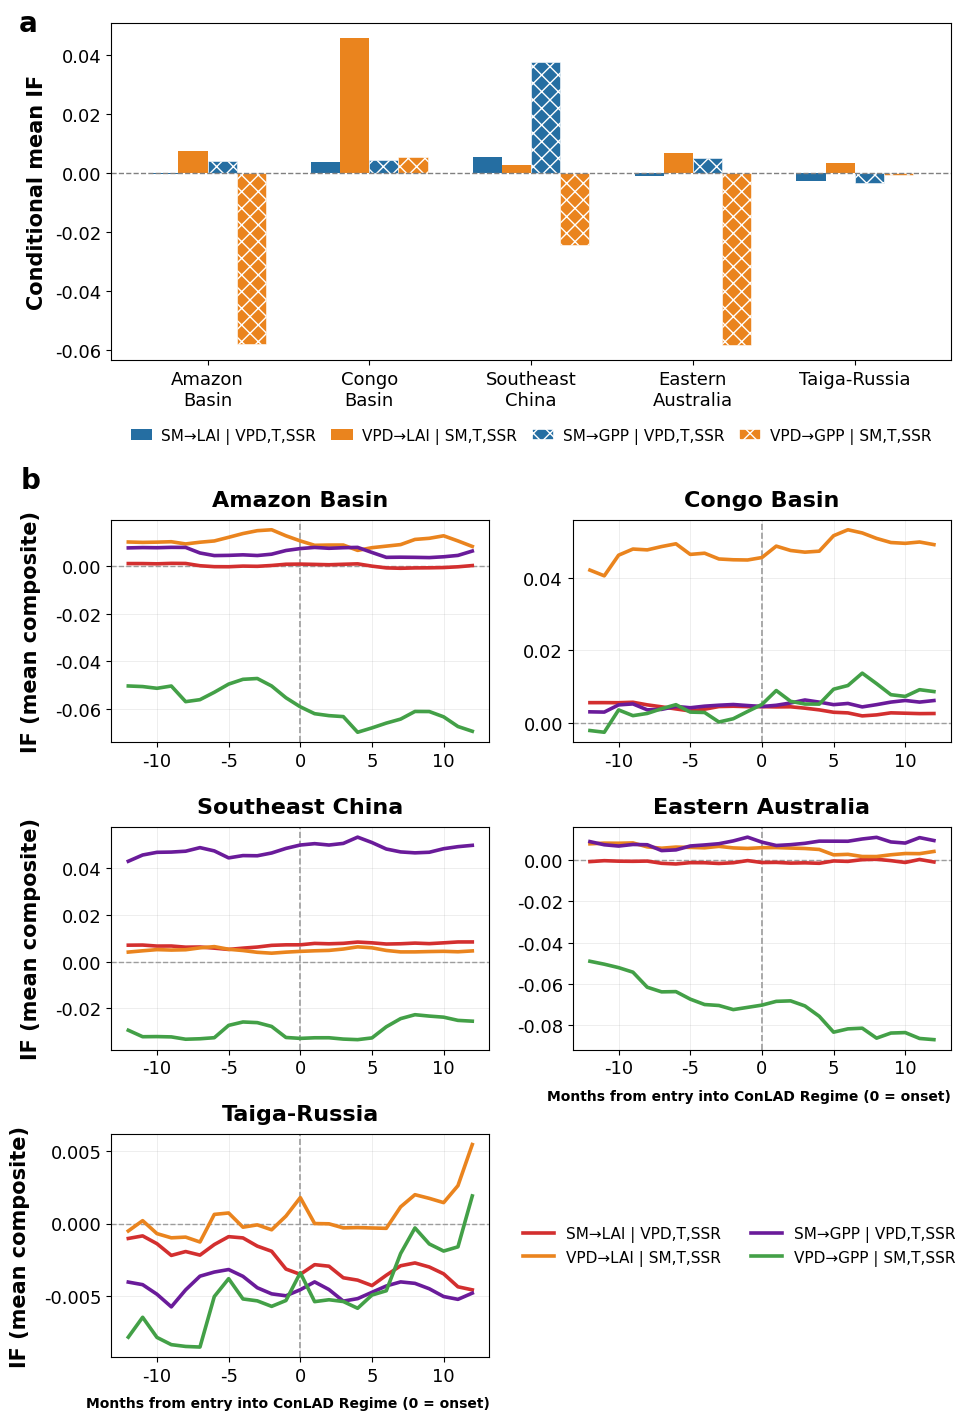

In [7]:
#3 a-b merged

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from pathlib import Path
import scipy.io as sio
import re
import matplotlib as mpl

# ---- Typography ----
mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 13,                # Base structural font size
    "axes.titlesize": 16,           # Box titles
    "axes.titleweight": "bold",
    "axes.labelsize": 15,           # Main labels
    "axes.labelweight": "bold",     
    "xtick.labelsize": 13,          
    "ytick.labelsize": 13,          
    "legend.fontsize": 11,          
    "mathtext.default": "regular",  
    "axes.unicode_minus": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,

    # Black text enforcement
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.edgecolor": "black",
    "axes.axisbelow": True,
})

# Structural element parameters
SPINE_W = 0.8
TICK_W  = 0.8
GRID_W  = 0.6
mpl.rcParams.update({
    "axes.linewidth": SPINE_W,
    "grid.linewidth": GRID_W,
    "xtick.major.width": TICK_W,
    "ytick.major.width": TICK_W,
})

# Line metrics matching
LINE_W        = 2.6   
ZERO_VLINE_W  = 1.2   
ZERO_HLINE_W  = 1.0   

# ---------------- Paths ----------------
BASE = Path("E:/CAZ-Again")
mat_path = BASE / "Fareeha_data_SM_VPD_1981_2018.mat"
if_path  = BASE / "IF_Couplings.xlsx"

FIG_DIR = BASE / "Figure3"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SAVE_DPI   = 400
BOX_EXPAND = 1.06
PAD_INCHES = 0.06

def _safe(name: str) -> str:
    return re.sub(r'[^A-Za-z0-9._-]+', '_', name).strip('_')

# ---------------- Figure A Configuration Data ----------------
REGIONS_A = ["Amazon","Congo","China","QL","Taiga"]
REGION_PRETTY_A = {
    "Amazon": "Amazon Basin", "Congo": "Congo Basin",
    "China": "Southeast China", "QL": "Eastern Australia", "Taiga": "Russia's Taiga"
}
REGION_TICKLABELS_MAP_A = {
    "Amazon Basin": "Amazon\nBasin", "Congo Basin": "Congo\nBasin",
    "Southeast China": "Southeast\nChina", "Eastern Australia": "Eastern\nAustralia",
    "Russia's Taiga": "Taiga-Russia",
}
COUPLINGS_A = [
    ("LAI", "SM→LAI | VPD,T,SSR", "SM-LAI|VPD,T,SSR"),
    ("LAI", "VPD→LAI | SM,T,SSR", "VPD-LAI|SM,T,SSR"),
    ("GPP", "SM→GPP | VPD,T,SSR", "SM-GPP|VPD,T,SSR"),
    ("GPP", "VPD→GPP | SM,T,SSR", "VPD-GPP|SM,T,SSR"),
]
COUPLING_SHORT_A = {
    "SM→LAI | VPD,T,SSR": "SM→LAI | VPD,T,SSR", "VPD→LAI | SM,T,SSR": "VPD→LAI | SM,T,SSR",
    "SM→GPP | VPD,T,SSR": "SM→GPP | VPD,T,SSR", "VPD→GPP | SM,T,SSR": "VPD→GPP | SM,T,SSR",
}

def drought_matrix(summary_df, order, couplings):
    M = np.zeros((len(order), len(couplings)))
    for i, rpretty in enumerate(order):
        for j, (_, pretty, _) in enumerate(couplings):
            v = summary_df.loc[(summary_df["Region"]==rpretty) & (summary_df["Coupling"]==pretty), "MeanIF"]
            M[i, j] = float(v.values[0]) if not v.empty else 0.0
    return M

SM_HEX_A  = "#256EA2"
VPD_HEX_A = "#ea841e"
WHITE_HATCH_HEX = "#ffffff"

COUPLING_STYLE_A = {
    "SM→LAI | VPD,T,SSR": {"color": SM_HEX_A,  "alpha": 1.0, "hatch": "",   "hatch_color": "none"},
    "SM→GPP | VPD,T,SSR": {"color": SM_HEX_A,  "alpha": 1.0, "hatch": "xx", "hatch_color": WHITE_HATCH_HEX},  
    "VPD→LAI | SM,T,SSR": {"color": VPD_HEX_A, "alpha": 1.0, "hatch": "",   "hatch_color": "none"},
    "VPD→GPP | SM,T,SSR": {"color": VPD_HEX_A, "alpha": 1.0, "hatch": "xx", "hatch_color": WHITE_HATCH_HEX} 
}

# ---------------- Figure B Configuration Data ----------------
regions_b = ["Amazon Basin","Congo Basin","Southeast China","Eastern Australia","Taiga-Russia"]
REG_MAP_IN_B = {"Amazon Basin": "Amazon", "Congo Basin": "Congo", "Southeast China": "China", "Eastern Australia": "QL", "Taiga-Russia": "Taiga"}
NAME_MAP_XLS = {"AMAZON": "Amazon", "CONGO": "Congo", "CHINA": "China", "AUSTRALIA": "QL", "WET TROPICS - AUSTRALIA": "QL", "RUSSIA": "Taiga", "RUSSIA'S TAIGA": "Taiga", "TAIGA": "Taiga"}

cmap_b = {"SM→LAI | VPD,T,SSR": "#D32F2F", "VPD→LAI | SM,T,SSR": "#ea841e", "SM→GPP | VPD,T,SSR": "#6A1B9A", "VPD→GPP | SM,T,SSR": "#43A047"}
order_b = ["SM→LAI | VPD,T,SSR", "VPD→LAI | SM,T,SSR", "SM→GPP | VPD,T,SSR", "VPD→GPP | SM,T,SSR"]

DROUGHT_NAME = "Drought–Demand"
XLABEL_TEXT_B = "Months from entry into ConLAD Regime (0 = onset)"
YLABEL_TEXT_B = "IF (mean composite)"

# ================================ DATA CONTEXT LAYER =====================================
mat = sio.loadmat(str(mat_path), squeeze_me=True)

def get_series(prefix, region_key):
    keys = {k.lower(): k for k in mat.keys()}
    want = f"{prefix}_{region_key}".lower()
    if want in keys:
        arr = np.ravel(np.array(mat[keys[want]], dtype=float))
        idx = pd.period_range("1982-01","2018-12",freq="M").to_timestamp()
        n = min(len(arr), len(idx))
        return pd.Series(arr[:n], index=idx[:n], name=prefix)
    return None

drivers = {}
for r in REGIONS_A:
    sm = get_series("SM", r); vpd = get_series("VPD", r)
    if sm is not None and vpd is not None:
        drivers[r] = {"SM": sm.astype(float), "VPD": vpd.astype(float)}

for r in regions_b:
    rk = REG_MAP_IN_B[r]
    if rk not in drivers:
        sm = get_series("SM", rk); vpd = get_series("VPD", rk)
        if sm is not None and vpd is not None:
            drivers[rk] = {"SM": sm.astype(float), "VPD": vpd.astype(float)}

LAI_df = pd.read_excel(if_path, sheet_name="SM'VPD-LAI", header=[0,1])
GPP_df = pd.read_excel(if_path, sheet_name="SM'VPD-GPP", header=[0,1])

def fix_time(df):
    t = pd.to_datetime(df.iloc[:,0], errors="coerce")
    if t.isna().all():
        t = pd.to_datetime(df.iloc[:,0], unit="D", origin="1899-12-30", errors="coerce")
    return df.set_index(t.dt.to_period("M").dt.to_timestamp()).iloc[:,1:]

LAI_df = fix_time(LAI_df); GPP_df = fix_time(GPP_df)

def pick_if_series(df, canon_region, pattern):
    for (reg_lbl, key) in df.columns:
        if NAME_MAP_XLS.get(reg_lbl, reg_lbl.title()) == canon_region and key == pattern:
            s = df[(reg_lbl, key)].astype(float).copy()
            s.index = s.index.to_period("M").to_timestamp()
            return s.groupby(s.index).mean()
    return None

def classify_regimes(sm, vpd):
    df = pd.concat([sm.rename("SM"), vpd.rename("VPD")], axis=1).dropna()
    qsm1,qsm2 = df.SM.quantile([1/3,2/3]); qv1,qv2 = df.VPD.quantile([1/3,2/3])
    reg = pd.Series("Other", index=df.index, dtype=object)
    reg[(df.SM<=qsm1) & (df.VPD>=qv2)] = "Drought–Demand"
    reg[(df.SM>=qsm2) & (df.VPD<=qv1)] = "Wet–Relief"
    reg[(df.SM<=qsm1) & (df.VPD<=qv1)] = "Mixed-Low"
    reg[(df.SM>=qsm2) & (df.VPD>=qv2)] = "Mixed-High"
    return df.index, reg

# Processing structural metrics for Matrix A
summary_rows = []
for reg in REGIONS_A:
    sm = drivers[reg]["SM"]; vpd = drivers[reg]["VPD"]
    _, regimes = classify_regimes(sm, vpd)
    for target, pretty, key in COUPLINGS_A:
        dfIF = LAI_df if target=="LAI" else GPP_df
        s_if = pick_if_series(dfIF, reg, key.replace("→","-").replace(" | ", "|"))
        if s_if is None: continue
        s_if = s_if.reindex(sm.index)
        dfj = pd.concat([s_if.rename("IF"), regimes.rename("Regime")], axis=1).dropna()
        if dfj.empty: continue
        means = dfj.groupby("Regime")["IF"].mean()
        if DROUGHT_NAME in means.index:
            summary_rows.append({"Region": REGION_PRETTY_A[reg], "Coupling": pretty, "MeanIF": float(means.loc[DROUGHT_NAME])})

summary_A = pd.DataFrame(summary_rows)
region_order_A = ["Amazon Basin", "Congo Basin", "Southeast China", "Eastern Australia", "Russia's Taiga"]
M_A = drought_matrix(summary_A, region_order_A, COUPLINGS_A)

# Processing tracking curves for Composite B
IFs_B = {}
regime_ts_B = {}
for r in regions_b:
    rk = REG_MAP_IN_B[r]
    sm = drivers[rk]["SM"]; vpd = drivers[rk]["VPD"]
    _, regimes = classify_regimes(sm, vpd)
    regime_ts_B[r] = regimes.replace("Drought–Demand", "Drought Regime")
    IFs_B[r] = {}
    s1 = pick_if_series(LAI_df, rk, "SM-LAI|VPD,T,SSR")
    s2 = pick_if_series(LAI_df, rk, "VPD-LAI|SM,T,SSR")
    s3 = pick_if_series(GPP_df, rk, "SM-GPP|VPD,T,SSR")
    s4 = pick_if_series(GPP_df, rk, "VPD-GPP|SM,T,SSR")
    idx = sm.index
    if s1 is not None: IFs_B[r]["SM→LAI | VPD,T,SSR"] = s1.reindex(idx)
    if s2 is not None: IFs_B[r]["VPD→LAI | SM,T,SSR"] = s2.reindex(idx)
    if s3 is not None: IFs_B[r]["SM→GPP | VPD,T,SSR"] = s3.reindex(idx)
    if s4 is not None: IFs_B[r]["VPD→GPP | SM,T,SSR"] = s4.reindex(idx)

# ================================ MASTER PLOTTING LAYOUT =====================================
fig = plt.figure(figsize=(10, 14.5))

subfigs = fig.subfigures(2, 1, height_ratios=[1.3, 2.7], hspace=0.01)

# ----------------- MASTER ROW 1: FIGURE A -----------------
subfig_A = subfigs[0]
ax_A = subfig_A.subplots(1, 1)

ax_A.text(-0.11, 1.04, "a", transform=ax_A.transAxes, fontsize=20, fontweight="bold", va="top")

GROUP_WIDTH = 0.72
n_regions, n_couplings = M_A.shape
x_A = np.arange(n_regions)
bar_w = GROUP_WIDTH / n_couplings
offsets_A = (np.arange(n_couplings) - (n_couplings-1)/2) * bar_w
region_ticklabels_A = [REGION_TICKLABELS_MAP_A[r] for r in region_order_A]

ax_A.set_ylabel("Conditional mean IF", labelpad=6, fontweight="bold")
handles_A, labels_A = [], []

for j, (_, pretty, _) in enumerate(COUPLINGS_A):
    yvals = M_A[:, j]
    style = COUPLING_STYLE_A[pretty]
    with plt.rc_context({'hatch.color': style['hatch_color']}):
        bars = ax_A.bar(x_A + offsets_A[j], yvals, bar_w, label=COUPLING_SHORT_A[pretty],
                        color=style["color"], edgecolor=style['hatch_color'] if style['hatch'] else 'none', 
                        linewidth=0.4 if style['hatch'] else 0, alpha=style["alpha"], hatch=style["hatch"])
    handles_A.append(Rectangle((0,0), 1, 1, facecolor=style["color"], alpha=style["alpha"], hatch=style["hatch"], 
                               edgecolor=style['hatch_color'] if style['hatch'] else 'none', linewidth=1.2 if style['hatch'] else 0))
    labels_A.append(COUPLING_SHORT_A[pretty])

ax_A.axhline(0, color="0.5", linewidth=1, linestyle="--")
ax_A.set_xticks(x_A)
ax_A.set_xticklabels(region_ticklabels_A, color="black")
ax_A.spines[['top','right','left','bottom']].set_color('black')
plt.setp(ax_A.get_yticklabels(), fontweight="normal")

ax_A.legend(handles=handles_A, labels=labels_A, ncol=len(COUPLINGS_A), frameon=False,
            loc="upper center", bbox_to_anchor=(0.5, -0.16), handlelength=1.4, handletextpad=0.6, columnspacing=1.0)
subfig_A.subplots_adjust(bottom=0.20, top=0.92, left=0.12, right=0.96)


# ----------------- MASTER ROW 2: FIGURE B -----------------
subfig_B = subfigs[1]
axes_B = subfig_B.subplots(3, 2)
axes_B_flat = axes_B.ravel()

# ADJUSTMENT: Shifted label 'b'
axes_B_flat[0].text(-0.24, 1.24, "b", transform=axes_B_flat[0].transAxes, fontsize=20, fontweight="bold", va="top")

def plot_region_b(ax, region_name):
    ax.set_axisbelow(True)
    ax.axvline(0, ls="--", lw=ZERO_VLINE_W, color="0.6", zorder=0)
    ax.axhline(0, ls="--", lw=ZERO_HLINE_W, color="0.6", zorder=0)
    entries = find_entries(regime_ts_B[region_name], "Drought Regime", PERSIST)
    t = np.arange(-WINDOW, WINDOW+1)
    for key in order_b:
        s = IFs_B[region_name].get(key, None)
        if s is None: continue
        m = composite_mean(s, entries, WINDOW)
        if m is not None: ax.plot(t, m, linewidth=LINE_W, label=key, color=cmap_b[key], zorder=3)
    ax.set_xticks([-10, -5, 0, 5, 10])
    ax.grid(True, which="both", axis="both", alpha=0.25, zorder=0)
    ax.set_title(region_name, pad=10)

for i, reg in enumerate(regions_b):
    plot_region_b(axes_B_flat[i], reg)

# Clean out unused cell components
axes_B_flat[-1].axis("off")

for i in range(5):
    ax = axes_B_flat[i]
    ax.set_xlabel("")
    ax.set_ylabel("")

for r in range(3):
    axes_B[r, 0].set_ylabel(YLABEL_TEXT_B, labelpad=10)

# Apply individual loc="right" x-axis labels exactly as formatted in separate files
axes_B[2, 0].set_xlabel(XLABEL_TEXT_B, labelpad=8, fontsize=10, fontweight="bold", loc="right")  # Left Column Bottom
axes_B[1, 1].set_xlabel(XLABEL_TEXT_B, labelpad=8, fontsize=10, fontweight="bold", loc="right")  # Right Column Bottom

# Build two-row composite legend in subfigure block context
handles_b = [Line2D([0],[0], color=cmap_b[k], lw=LINE_W) for k in order_b]
axes_B_flat[-1].legend(handles_b, order_b, ncol=2, loc="center", bbox_to_anchor=(0.44, 0.5), frameon=False)

subfig_B.subplots_adjust(bottom=0.08, top=0.94, left=0.12, right=0.96, hspace=0.38, wspace=0.22)


# ================================ MASTER EXPORT LAYER =====================================
master_png = FIG_DIR / "Combined_Figure3_Master.png"
master_pdf = FIG_DIR / "Combined_Figure3_Master.pdf"
fig.savefig(master_png, dpi=SAVE_DPI, bbox_inches="tight", pad_inches=PAD_INCHES)
fig.savefig(master_pdf, bbox_inches="tight", pad_inches=PAD_INCHES)
print(f"[Master Combined Figure Saved Successfully] {master_png}")

plt.show()